# Iris Flower Classification

## OASIS INFOBYTE — Data Science Internship

### Task 1: Iris Flower Classification

**Objective:** Build machine learning classification models to identify Iris flower species — Setosa, Versicolor, and Virginica — using their physical measurements.   

## 1. Introduction

The Iris flower dataset is a classic dataset used for machine learning classification.

The objective of this project is to build classification models that can identify the species of an Iris flower based on its physical measurements.

The three species are:
- Setosa
- Versicolor
- Virginica

The features used for classification are:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width 

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris 

In [2]:
# Load the Iris dataset

iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the target/species column
df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Basic dataset inspection

print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (150, 5)

Data Types:
sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [4]:
# Descriptive statistics

df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


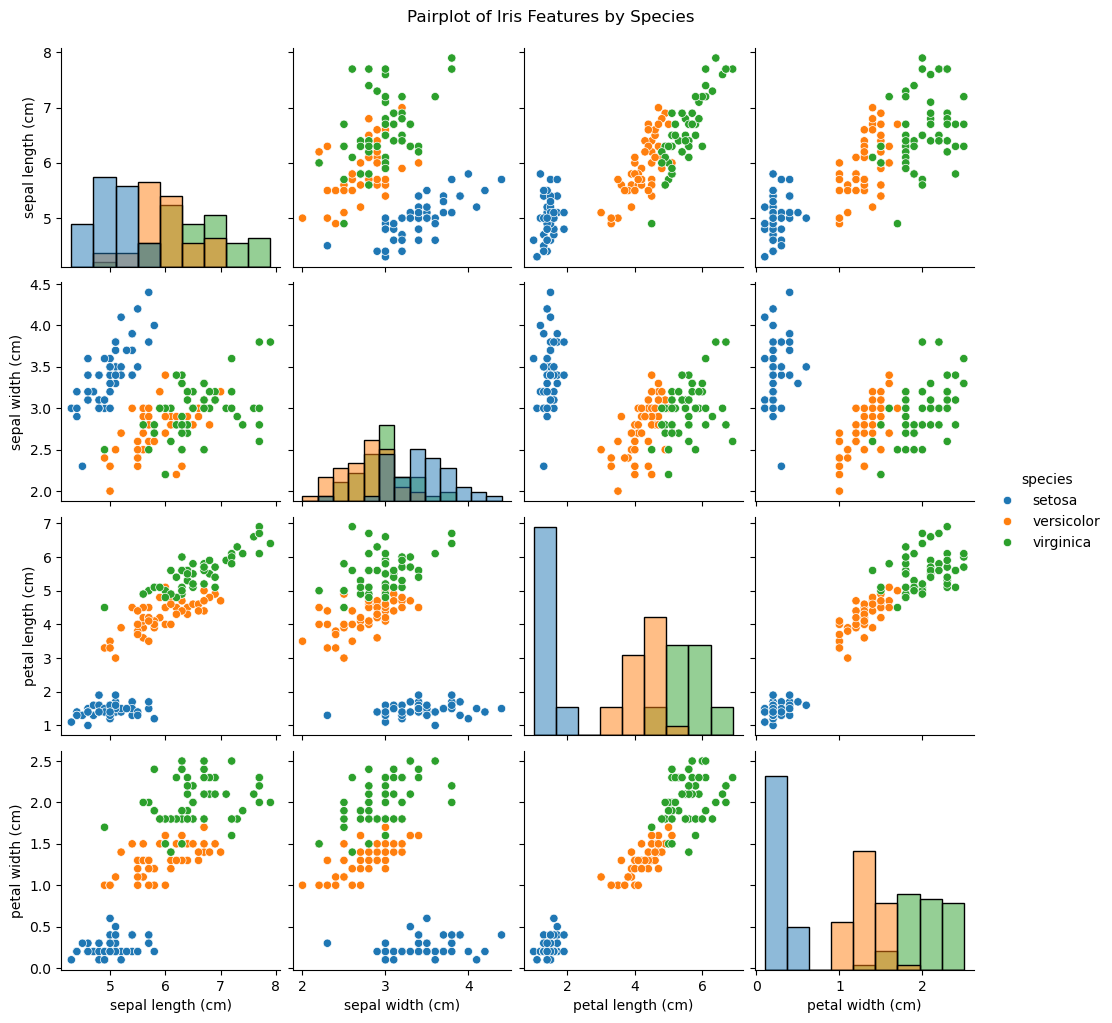

In [5]:
# Pairplot to visualize relationships between features by species

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

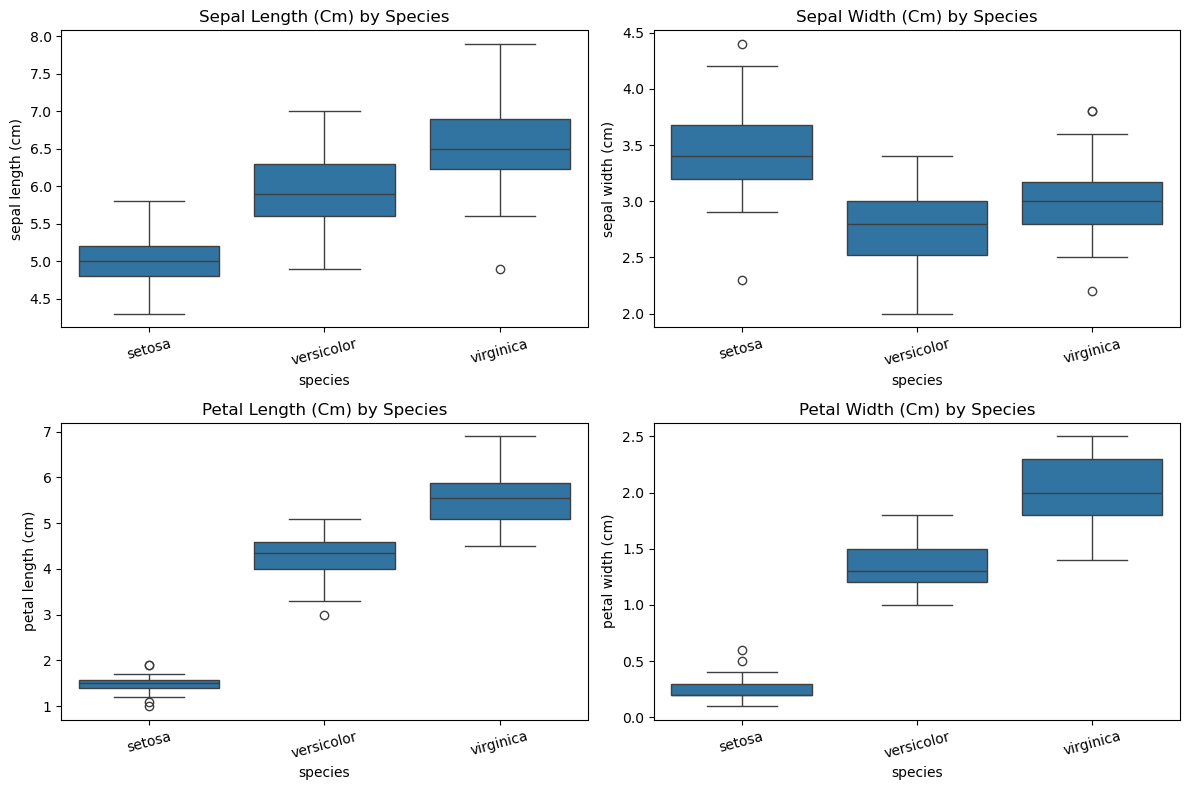

In [6]:
# Box plots for each numerical feature

features = iris.feature_names

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x="species", y=feature)
    plt.title(f"{feature.title()} by Species")
    plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## 2. Feature Selection Discussion

From the pairplot and box plots, petal length and petal width show clearer separation between the three Iris species compared with the sepal measurements.

The petal-related features therefore appear to be the most discriminative features for distinguishing Setosa, Versicolor, and Virginica.

We will retain all four features for model training and allow the classification models to learn their relative importance.

In [8]:
# Prepare features and target

from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = df["species"]

# Split data into training and testing sets (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (120, 4)
Testing data shape: (30, 4)


In [9]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=200)

logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [10]:
# Evaluate Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", logistic_accuracy)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [11]:
# Train K-Nearest Neighbors (KNN) model

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)

print("KNN model trained successfully.")

KNN model trained successfully.


In [12]:
# Evaluate KNN

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [13]:
# Compare model performance

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [logistic_accuracy, knn_accuracy]
})

model_comparison

,Model,Accuracy
0,Logistic Regression,0.966667
1,KNN,1.000000


## 3. Model Comparison and Best Model

Two classification models were trained and evaluated:

| Model | Accuracy |
|---|---:|
| Logistic Regression | 96.67% |
| K-Nearest Neighbors (KNN) | 100.00% |

### Best-Performing Model

Based on the accuracy obtained on the test set, K-Nearest Neighbors (KNN) performed better than Logistic Regression for this experiment.

KNN achieved an accuracy of 100%, correctly classifying all 30 test samples, while Logistic Regression achieved an accuracy of 96.67%, with one misclassified sample.

Therefore, KNN is selected as the best-performing model for this test split.

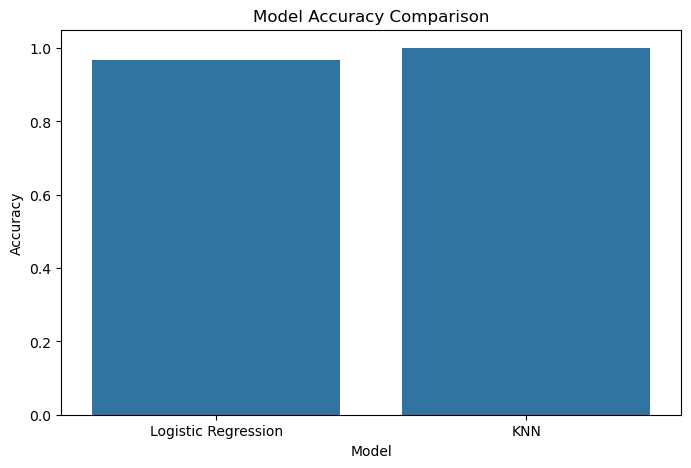

In [14]:
# Visual comparison of model accuracy

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1.05)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.show()

## 4. Conclusion

In this project, the Iris flower dataset was explored and analyzed using descriptive statistics and visualizations.

Two machine learning classification models were trained:

- Logistic Regression
- K-Nearest Neighbors (KNN)

Both models performed well on the test dataset. Logistic Regression achieved an accuracy of 96.67%, while KNN achieved 100.00% accuracy on the 30-sample test set.

Based on the results of this experiment, KNN was selected as the best-performing model because it correctly classified all test samples.

The analysis also showed that petal length and petal width provided clearer separation between the Iris species compared with the sepal measurements.